# Qualidade dos dados de chamados de manejo de árvores (1746, Rio de Janeiro)

**Projeto de extensão:** Ciência de Dados para Cidades Inteligentes (IM-UFRJ)
**Autor:** josé

Este notebook faz o levantamento da base de chamados do 1746 sobre árvores e responde quatro perguntas:

1. **Para que serve a base?** (objetivo)
2. **Que tipo de dado tem em cada coluna?** (texto, número decimal/float, data...)
3. **A base está completa e correta?** (dados faltando, valores impossíveis, repetições)
4. **As colunas concordam entre si?** (discrepâncias: uma coluna contradiz outra)

No fim há um **sumário** com tudo o que foi encontrado e o que fazer com cada problema.

**Como rodar no Colab:** clique em *Ambiente de execução → Executar tudo*. Na primeira célula de código, o Colab pede para você enviar os arquivos CSV (as partes `chamados_completo_com_cep_parte*.csv` e, se tiver, `dados_finais_setor_v3.csv`).

## 0. Preparação: carregar os dados

A base veio dividida em partes (`parte1de4`, `parte2de4`...). O código junta todas as partes que encontrar.
O arquivo `dados_finais_setor_v3.csv` (do grupo de arborização) é opcional: ele traz o **nome do bairro** de cada setor do Censo, que usamos para comparar bairros na seção 4.

In [1]:
import glob, os, unicodedata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 80)

# No Colab: se os arquivos ainda não estão na pasta, abre a janela para enviar.
if not glob.glob('chamados_completo_com_cep_parte*.csv'):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        pass  # fora do Colab: coloque os CSVs na mesma pasta do notebook

partes = sorted(glob.glob('chamados_completo_com_cep_parte*.csv'))
print('Partes encontradas:', partes)

# Lemos tudo como texto primeiro, para ver os tipos "crus" e decidir o tipo certo depois.
bruto = pd.concat([pd.read_csv(p, dtype=str) for p in partes], ignore_index=True)
print(f'{len(bruto):,} chamados e {bruto.shape[1]} colunas'.replace(',', '.'))

Partes encontradas: ['chamados_completo_com_cep_parte3de4.csv']


42.455 chamados e 41 colunas


In [2]:
# Como o pandas leria cada coluna sozinho (sem a nossa ajuda):
automatico = pd.concat([pd.read_csv(p, low_memory=False) for p in partes], ignore_index=True)
automatico.dtypes.value_counts()

str        21
float64    12
int64       7
bool        1
Name: count, dtype: int64

## 1. Objetivo da base

Cada linha é **um chamado** feito por um cidadão (telefone, aplicativo ou site) na Central 1746 da Prefeitura do Rio. Esta extração traz só o tipo **"Manejo Arbóreo"**: pedidos de poda, remoção de árvore, avaliação de risco de queda e retirada de árvore caída.

**Para que vamos usar:** o ciclo 1 do projeto quer **prever quantos pedidos de poda** cada rua (logradouro) terá em cada mês. Para isso precisamos saber:
- **onde** foi o pedido (bairro, logradouro, coordenadas, CEP, setor censitário);
- **quando** foi aberto e fechado (datas);
- **o que** foi pedido (subtipo) e **o que aconteceu** (status).

Por isso a checagem dá mais atenção a essas colunas.

In [3]:
# Período coberto e tipos de pedido
ini = pd.to_datetime(bruto['data_inicio'], errors='coerce')
print('Primeiro chamado:', ini.min(), '| Último:', ini.max())
print('\nChamados por mês de abertura:')
print(ini.dt.to_period('M').value_counts().sort_index().to_string())

Primeiro chamado: 2023-01-01 10:46:36 | Último: 2026-05-31 23:33:28

Chamados por mês de abertura:
data_inicio
2023-01    4954
2023-05    3714
2023-07    2420
2024-02    3853
2024-03    4290
2024-04    3892
2024-05    3205
2024-06    3102
2025-06    2861
2025-07    2836
2026-03    4292
2026-05    3036
Freq: M


> **Atenção:** se aparecerem só alguns meses (e não todos), é porque cada parte do arquivo cobre meses diferentes. Para estudar tendências ao longo do tempo é preciso juntar **todas** as partes.

## 2. Dicionário de dados: o que é cada coluna e qual o tipo certo

Tipos usados:
- **inteiro**: número sem vírgula (ex.: quantidade de reclamações);
- **float** (decimal): número com vírgula (ex.: latitude −22,83);
- **data/hora**: momento no tempo (ex.: 2023-07-13 14:53);
- **texto (categoria)**: poucos valores que se repetem (ex.: status);
- **código**: parece número, mas é um **identificador**. Não faz sentido somar ou tirar média de um CEP. Guardamos como texto.
- **lógico**: verdadeiro ou falso.

A tabela abaixo compara o tipo que o pandas "adivinha" com o tipo certo.

In [4]:
dicionario = {
 'id_chamado':('código','Número do chamado (deve ser único)'),
 'id_origem_ocorrencia':('código','Canal de entrada do chamado (telefone, app...)'),
 'data_inicio':('data/hora','Quando o chamado foi aberto'),
 'data_fim':('data/hora','Quando o chamado foi fechado (vazio = ainda aberto)'),
 'id_bairro':('código','Bairro informado no 1746'),
 'id_territorialidade':('código','Região de atendimento'),
 'id_logradouro':('código','Rua/avenida informada no 1746'),
 'numero_logradouro':('inteiro','Número da casa/prédio'),
 'id_unidade_organizacional':('código','Órgão responsável'),
 'nome_unidade_organizacional':('texto (categoria)','Nome do órgão responsável'),
 'id_unidade_organizacional_mae':('código','Órgão "pai"'),
 'unidade_organizacional_ouvidoria':('lógico','Se o órgão é uma ouvidoria'),
 'categoria':('texto (categoria)','Serviço, Reclamação, Elogio...'),
 'id_tipo':('código','Código do tipo'),
 'tipo':('texto (categoria)','Tipo do chamado (aqui sempre Manejo Arbóreo)'),
 'id_subtipo':('código','Código do subtipo'),
 'subtipo':('texto (categoria)','O que foi pedido (poda, remoção...)'),
 'status':('texto (categoria)','Situação detalhada do chamado'),
 'longitude':('float','Coordenada original do chamado'),
 'latitude':('float','Coordenada original do chamado'),
 'data_alvo_finalizacao':('data/hora','Prazo para terminar'),
 'data_alvo_diagnostico':('data/hora','Prazo para diagnóstico'),
 'data_real_diagnostico':('data/hora','Quando o diagnóstico foi feito'),
 'tempo_prazo':('inteiro','Tamanho do prazo'),
 'prazo_unidade':('texto (categoria)','Unidade do prazo (D = dias)'),
 'prazo_tipo':('texto (categoria)','Tipo do prazo (F/D)'),
 'dentro_prazo':('texto (categoria)','Situação do prazo segundo o 1746'),
 'situacao':('texto (categoria)','Encerrado ou Não Encerrado'),
 'tipo_situacao':('texto (categoria)','Atendido, Não atendido...'),
 'justificativa_status':('texto','Motivo do status'),
 'reclamacoes':('inteiro','Quantas reclamações o chamado recebeu'),
 'extracted_at':('data/hora','Quando a linha foi extraída do sistema'),
 'updated_at':('data/hora','Última atualização do chamado'),
 'data_particao':('data','Dia de abertura (usado para dividir a tabela no BigQuery)'),
 'latitude_usada':('float','Coordenada usada pelo grupo (original ou estimada pelo endereço)'),
 'longitude_usada':('float','Coordenada usada pelo grupo'),
 'cd_setor':('código','Setor censitário do IBGE onde o ponto cai'),
 'cep':('código','CEP mais próximo do ponto'),
 'cep_logradouro_ref':('texto','Rua do CEP de referência'),
 'cep_bairro_ref':('texto','Bairro do CEP de referência'),
 'dist_km_ao_cep':('float','Distância (km) entre o ponto e o CEP de referência'),
}
tipo_pandas = automatico.dtypes.astype(str).replace({'object':'texto','str':'texto','float64':'float','int64':'inteiro','bool':'lógico'})
dic = pd.DataFrame({
    'significado': {c: v[1] for c, v in dicionario.items()},
    'tipo lido pelo pandas': tipo_pandas,
    'tipo certo': {c: v[0] for c, v in dicionario.items()},
})
dic['precisa converter?'] = np.where(dic['tipo lido pelo pandas'] == dic['tipo certo'], '', 'sim')
dic

,significado,tipo lido pelo pandas,tipo certo,precisa converter?
id_chamado,Número do chamado (deve ser único),inteiro,código,sim
id_origem_ocorrencia,"Canal de entrada do chamado (telefone, app...)",inteiro,código,sim
data_inicio,Quando o chamado foi aberto,texto,data/hora,sim
data_fim,Quando o chamado foi fechado (vazio = ainda aberto),texto,data/hora,sim
id_bairro,Bairro informado no 1746,float,código,sim
id_territorialidade,Região de atendimento,float,código,sim
id_logradouro,Rua/avenida informada no 1746,float,código,sim
numero_logradouro,Número da casa/prédio,float,inteiro,sim
id_unidade_organizacional,Órgão responsável,inteiro,código,sim
nome_unidade_organizacional,Nome do órgão responsável,texto,texto (categoria),sim


**O que a tabela mostra:**
- As **datas** chegam como texto. Sem converter, não dá para calcular tempo de atendimento.
- Vários **códigos** (`id_bairro`, `id_logradouro`, `cd_setor`, `cep`) chegam como **float** (ex.: `75.0`). Isso acontece porque a coluna tem valores vazios, e no pandas o vazio só cabe em coluna decimal. Um CEP como float pode até perder o zero da frente. Por isso convertemos para texto.
- `numero_logradouro` também vira float pelo mesmo motivo.

A célula abaixo faz a conversão e cria a tabela `df`, que é a usada no resto do notebook.

In [5]:
df = bruto.copy()

colunas_data = ['data_inicio','data_fim','data_alvo_finalizacao','data_alvo_diagnostico',
                'data_real_diagnostico','updated_at','data_particao']
for c in colunas_data:
    df[c] = pd.to_datetime(df[c], errors='coerce')
df['extracted_at'] = pd.to_datetime(df['extracted_at'], errors='coerce', utc=True).dt.tz_localize(None)

for c in ['latitude','longitude','latitude_usada','longitude_usada','dist_km_ao_cep']:
    df[c] = pd.to_numeric(df[c], errors='coerce')                       # float
for c in ['numero_logradouro','tempo_prazo','reclamacoes']:
    df[c] = pd.to_numeric(df[c], errors='coerce').astype('Int64')         # inteiro que aceita vazio

def codigo(s):  # '75.0' -> '75'; vazio continua vazio
    return pd.to_numeric(s, errors='coerce').astype('Int64').astype('string')
for c in ['id_chamado','id_origem_ocorrencia','id_bairro','id_territorialidade','id_logradouro',
          'id_unidade_organizacional','id_unidade_organizacional_mae','id_tipo','id_subtipo','cd_setor','cep']:
    df[c] = codigo(df[c])

df['unidade_organizacional_ouvidoria'] = df['unidade_organizacional_ouvidoria'].map({'True':True,'False':False})

# Quantos valores "quebraram" na conversão (texto que não era data/número de verdade)?
quebrados = {c: int((bruto[c].notna() & df[c].isna()).sum()) for c in dicionario}
print('Valores que não puderam ser convertidos:', {c: n for c, n in quebrados.items() if n} or 'nenhum')
df.dtypes.to_frame('tipo depois da conversão').T

Valores que não puderam ser convertidos: nenhum


,id_chamado,id_origem_ocorrencia,data_inicio,data_fim,id_bairro,id_territorialidade,id_logradouro,numero_logradouro,id_unidade_organizacional,nome_unidade_organizacional,...,extracted_at,updated_at,data_particao,latitude_usada,longitude_usada,cd_setor,cep,cep_logradouro_ref,cep_bairro_ref,dist_km_ao_cep
tipo depois da conversão,string,string,datetime64[us],datetime64[us],string,string,string,Int64,string,str,...,datetime64[us],datetime64[us],datetime64[us],float64,float64,string,string,str,str,float64


## 3. Qualidade coluna por coluna

### 3.1 Dados faltando
Quanto de cada coluna está vazio. Algumas colunas vazias são **normais** (ex.: `data_fim` vazia num chamado ainda aberto); outras são **problema** (ex.: chamado sem bairro).

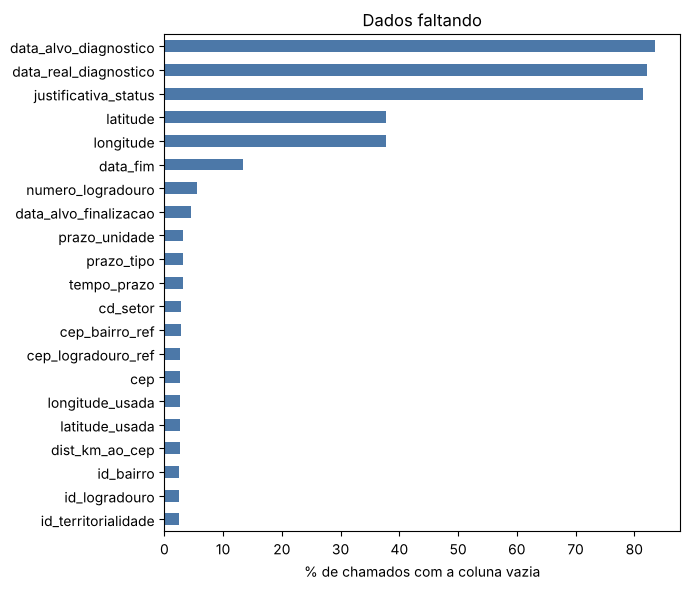

,% vazio
data_alvo_diagnostico,83.6
data_real_diagnostico,82.2
justificativa_status,81.4
latitude,37.8
longitude,37.8
data_fim,13.4
numero_logradouro,5.6
data_alvo_finalizacao,4.5
prazo_unidade,3.1
prazo_tipo,3.1


In [6]:
faltando = (df.isna().mean()*100).round(1).sort_values(ascending=False)
faltando = faltando[faltando > 0]
ax = faltando.plot.barh(figsize=(7, 6), color='#4C78A8')
ax.invert_yaxis(); ax.set_xlabel('% de chamados com a coluna vazia'); ax.set_title('Dados faltando')
plt.tight_layout(); plt.show()
faltando.to_frame('% vazio')

**Como ler:**
- `latitude`/`longitude` originais faltam em muitos chamados, mas `latitude_usada` quase sempre existe: o grupo **estimou** o ponto pelo endereço. Esses pontos estimados são menos precisos.
- `data_alvo_diagnostico`, `data_real_diagnostico` e `justificativa_status` quase sempre vazias: **não servem** para análise.
- `id_bairro` e `id_logradouro` vazios: esses chamados **não podem** ser colocados numa rua, o que afeta direto o objetivo (prever por rua e mês).

### 3.2 Chamados repetidos

In [7]:
print('id_chamado repetido:', df['id_chamado'].duplicated().sum())

# Mesmo endereço, mesmo dia e mesmo pedido: provável pedido duplicado
df['dia'] = df['data_inicio'].dt.date
chave = ['id_logradouro','numero_logradouro','dia','id_subtipo']
grupos = df.dropna(subset=chave).groupby(chave).size()
print('Chamados "extras" no mesmo endereço+dia+pedido:', int((grupos-1).sum()))
print('Endereços com 5 ou mais pedidos iguais no mesmo dia ("lotes"):', int((grupos>=5).sum()),
      '| chamados nesses lotes:', int(grupos[grupos>=5].sum()))
grupos.sort_values(ascending=False).head(10).to_frame('chamados')

id_chamado repetido: 0
Chamados "extras" no mesmo endereço+dia+pedido: 738
Endereços com 5 ou mais pedidos iguais no mesmo dia ("lotes"): 11 | chamados nesses lotes: 82


chamados
id_logradouro numero_logradouro dia        id_subtipo          
69500         146               2024-03-18 1321              20
                                2024-03-21 1321              11
37259         61                2025-07-14 1319               7
34652         2007              2023-07-14 1319               6
17152         7662              2023-05-24 1319               6
69500         146               2024-03-19 1320               6
196527        177               2023-05-10 1319               6
72892         25                2024-04-25 1321               5
72918         488               2026-03-16 1319               5
33621         173               2026-03-30 1319               5

Pedidos repetidos no mesmo dia não são necessariamente erro (vizinhos ligando pela mesma árvore), mas **inflam a contagem**. Para o modelo, a regra do grupo é guardar 1 chamado por "lote".

### 3.3 Categorias: o que existe em cada coluna de texto

In [8]:
for c in ['tipo','categoria','subtipo','status','situacao','tipo_situacao','dentro_prazo',
          'nome_unidade_organizacional','prazo_unidade','prazo_tipo','justificativa_status']:
    print(f'--- {c} ---')
    print(df[c].value_counts(dropna=False).to_string(), '\n')

--- tipo ---
tipo
Manejo Arbóreo    42455 

--- categoria ---
categoria
Serviço        36715
Reclamação      3203
Informações     1637
Crítica          761
Elogio            85
Sugestão          54 

--- subtipo ---
subtipo
Poda de árvore em logradouro             23395
Poda de árvore em vias públicas           6525
Remoção de árvore em logradouro           5404
Avaliação de risco de queda da árvore     4104
Retirada de árvore caída                  1336
Poda e remoção de árvore                  1182
Remoção de árvore em vias públicas         472
Árvore - Poda                               28
Árvore - Remoção                             9 

--- status ---
status
Fechado com solução                 21559
Sem possibilidade de atendimento     8002
Fechado com providências             4669
Pendente                             3656
Fechado com informação               2447
Em Andamento                         1990
Aberto                                 52
Não constatado                     

**O que chama atenção:**
- A base **mistura pedidos diferentes**: poda, remoção, avaliação de risco, árvore caída. Para estudar poda, filtramos só os subtipos de poda.
- O mesmo pedido aparece com **nomes diferentes**: "Poda de árvore em logradouro", "Poda de árvore em vias públicas" e "Árvore - Poda". O nome "logradouro" deixa de ser usado entre 2025 e 2026 (veja 4.4). Precisam ser **juntados**.
- `categoria` tem **Elogio, Crítica, Sugestão, Reclamação**: não são pedidos de serviço, são mensagens para a ouvidoria.

### 3.4 Valores impossíveis ou estranhos

In [9]:
lat, lon = df['latitude_usada'], df['longitude_usada']
fora_rio = (lat < -23.1) | (lat > -22.7) | (lon < -43.8) | (lon > -43.1)
print('Pontos fora da cidade do Rio:', int(fora_rio.sum()))
print(df.loc[fora_rio, ['id_chamado','latitude_usada','longitude_usada','cep_bairro_ref']].to_string(), '\n')

num = df['numero_logradouro']
print('Número do imóvel = 0:', int((num == 0).sum()))
print('Número do imóvel acima de 20.000 (provável erro de digitação):', int((num > 20000).sum()),
      '| maiores:', num.nlargest(3).tolist())

print('\nDistância ao CEP de referência (km):')
print(df['dist_km_ao_cep'].describe().round(3).to_string())
print('Chamados a mais de 1 km do CEP:', int((df['dist_km_ao_cep'] > 1).sum()))

dur = (df['data_fim'] - df['data_inicio']).dt.days
print('\nDias entre abertura e fechamento:'); print(dur.describe().round(1).to_string())
print('Fechados em menos de 1 hora:', int(((df['data_fim']-df['data_inicio']).dt.total_seconds() < 3600).sum()))
print('Mais de 1 ano para fechar:', int((dur > 365).sum()))
print('\nFechados em menos de 1 hora, por categoria:')
print(df.loc[(df['data_fim']-df['data_inicio']).dt.total_seconds() < 3600, 'categoria'].value_counts().to_string())

Pontos fora da cidade do Rio: 3
      id_chamado  latitude_usada  longitude_usada cep_bairro_ref
11328   22120789      -19.750711       -40.379902          Méier
28604   20042243      -22.790881       -43.048645       Sepetiba
38795   23484263      -22.672955       -43.269437         Cosmos 

Número do imóvel = 0: 2257
Número do imóvel acima de 20.000 (provável erro de digitação): 104 | maiores: [23575330, 6482856, 604658]

Distância ao CEP de referência (km):
count    41318.000
mean         0.077
std          0.343
min          0.000
25%          0.034
50%          0.065
75%          0.100
max         68.404
Chamados a mais de 1 km do CEP: 4

Dias entre abertura e fechamento:
count    36757.0
mean        95.2
std        193.4
min          0.0
25%          2.0
50%         13.0
75%         97.0
max       1328.0
Fechados em menos de 1 hora: 1619
Mais de 1 ano para fechar: 2691

Fechados em menos de 1 hora, por categoria:
categoria
Informações    1467
Serviço         151
Reclamação       

## 4. Discrepâncias: quando uma coluna contradiz outra

Aqui cruzamos colunas que **deveriam concordar**. Cada contradição é um sinal de erro no registro ou de regra do sistema que precisamos entender.

### 4.1 Datas em ordem

In [10]:
checks = {
 'fechamento antes da abertura': df['data_fim'] < df['data_inicio'],
 'prazo final antes da abertura': df['data_alvo_finalizacao'] < df['data_inicio'],
 'última atualização antes da abertura': df['updated_at'] < df['data_inicio'],
 'fechamento depois da extração': df['data_fim'] > df['extracted_at'],
 'dia da partição diferente do dia de abertura': df['data_particao'].dt.date != df['data_inicio'].dt.date,
}
pd.Series({k: int(v.sum()) for k, v in checks.items()}).to_frame('chamados com problema')

,chamados com problema
fechamento antes da abertura,0
prazo final antes da abertura,0
última atualização antes da abertura,0
fechamento depois da extração,0
dia da partição diferente do dia de abertura,0


### 4.2 Status x data de fechamento x situação

In [11]:
tab = pd.crosstab(df['status'], df['data_fim'].isna().map({True:'sem data_fim', False:'com data_fim'}))
tab['situacao'] = df.groupby('status')['situacao'].agg(lambda s: ', '.join(sorted(s.unique())))
tab

data_fim,com data_fim,sem data_fim,situacao
status,,,
Aberto,0,52,Não Encerrado
Cancelado,37,0,Encerrado
Em Andamento,0,1990,Não Encerrado
Fechado com informação,2447,0,Encerrado
Fechado com providências,4669,0,Encerrado
Fechado com solução,21559,0,Encerrado
Não constatado,43,0,Encerrado
Pendente,0,3656,Não Encerrado
Sem possibilidade de atendimento,8002,0,Encerrado


In [12]:
fechado = df['situacao'] == 'Encerrado'
print('Encerrado mas sem data de fechamento:', int((fechado & df['data_fim'].isna()).sum()))
print('Não encerrado mas com data de fechamento:', int((~fechado & df['data_fim'].notna()).sum()))
print('\n"Sem possibilidade de atendimento" por justificativa:')
print(df.loc[df['status']=='Sem possibilidade de atendimento','justificativa_status'].value_counts(dropna=False).to_string())
print('\nJustificativa preenchida em outros status:',
      int(df.loc[df['status']!='Sem possibilidade de atendimento','justificativa_status'].notna().sum()))

Encerrado mas sem data de fechamento: 0
Não encerrado mas com data de fechamento: 0

"Sem possibilidade de atendimento" por justificativa:
justificativa_status
Informações incorretas ou insuficientes não permitiram o tratamento do chamado    6184
Não há previsão para execução do serviço no local                                 1712
NaN                                                                                106

Justificativa preenchida em outros status: 0


Aqui as colunas **concordam**: o status bate com `situacao` e com a existência de `data_fim`. Mas repare:
- **"Fechado com providências"** e **"Fechado com informação"** contam como encerrados, mas não dizem se a árvore foi podada. Tratamos como "sem poda confirmada".
- A maior parte dos "Sem possibilidade de atendimento" é **"informações incorretas ou insuficientes"**: o pedido foi fechado porque o endereço/descrição estava ruim, não porque a árvore não precisava de poda.

### 4.3 Prazo: a coluna `dentro_prazo` está atualizada?

In [13]:
referencia = df['data_fim'].fillna(df['extracted_at'])   # fechamento, ou o dia da extração se ainda aberto
passou = (referencia > df['data_alvo_finalizacao']).map({True:'passou do prazo', False:'dentro do prazo'})
tab = pd.crosstab(df['dentro_prazo'], passou.rename('pelas datas'))
tab

pelas datas,dentro do prazo,passou do prazo
dentro_prazo,,
A Vencer (No Prazo),23662,1578
Em Vencimento (No Prazo),11057,297
Não Calculado,1471,0
Pendente de Programação,455,0
Vencido,0,3935


In [14]:
diz_no_prazo = df['dentro_prazo'].str.contains('No Prazo', na=False)
contradiz = diz_no_prazo & (referencia > df['data_alvo_finalizacao'])
print('Chamados marcados "No Prazo" que na verdade passaram do prazo:', int(contradiz.sum()),
      f'({contradiz.mean()*100:.1f}% da base)')

Chamados marcados "No Prazo" que na verdade passaram do prazo: 1875 (4.4% da base)


`dentro_prazo` é uma "foto" tirada em algum momento e **nem sempre foi atualizada**. Para medir atraso, é melhor **calcular** com as datas do que confiar nessa coluna.

### 4.4 O mesmo pedido com nomes diferentes ao longo do tempo

In [15]:
poda = ['Poda de árvore em logradouro','Poda de árvore em vias públicas','Árvore - Poda']
x = df[df['subtipo'].isin(poda)]
pd.crosstab(x['data_inicio'].dt.to_period('M'), x['subtipo'])

subtipo,Poda de árvore em logradouro,Poda de árvore em vias públicas,Árvore - Poda
data_inicio,,,
2023-01,3372,82,2
2023-05,2686,46,0
2023-07,1440,36,1
2024-02,2628,57,1
2024-03,2922,57,5
2024-04,2793,56,9
2024-05,2275,66,7
2024-06,2187,48,3
2025-06,1668,294,0


Se olharmos só um nome, parece que os pedidos "somem" ou "aparecem" de repente. É só **troca de nome no sistema**. Na análise juntamos os três como "pedido de poda".

### 4.5 Localização: os bairros concordam?

Temos três fontes de bairro para o mesmo chamado:
1. o **bairro informado no 1746** (`id_bairro`);
2. o **bairro do setor censitário** onde cai o ponto (`cd_setor`, nome vindo de `dados_finais_setor_v3.csv`);
3. o **bairro do CEP** mais próximo (`cep_bairro_ref`).

In [16]:
def normaliza(t):  # tira acento e maiúscula para comparar nomes
    if pd.isna(t): return t
    return unicodedata.normalize('NFKD', str(t)).encode('ascii', 'ignore').decode().lower().strip()

if os.path.exists('dados_finais_setor_v3.csv'):
    setor = pd.read_csv('dados_finais_setor_v3.csv', dtype={'cd_setor': str, 'codbairro': str})
    nome_setor = setor.set_index('cd_setor')['bairro']
    nome_bairro = setor.drop_duplicates('codbairro').set_index('codbairro')['bairro']
    df['bairro_ponto'] = df['cd_setor'].map(nome_setor)
    df['bairro_1746'] = df['id_bairro'].map(nome_bairro)

    a = df.dropna(subset=['bairro_1746','bairro_ponto'])
    print(f"Bairro do 1746 = bairro do ponto: {(a['bairro_1746']==a['bairro_ponto']).mean()*100:.1f}%")
    b = df.dropna(subset=['bairro_ponto','cep_bairro_ref'])
    igual = b['bairro_ponto'].map(normaliza) == b['cep_bairro_ref'].map(normaliza)
    print(f"Bairro do ponto = bairro do CEP: {igual.mean()*100:.1f}%")
    print('\nPares que mais discordam (ponto x CEP):')
    display(b[~igual][['bairro_ponto','cep_bairro_ref']].value_counts().head(12).to_frame('chamados'))
    print('Pares que mais discordam (1746 x ponto):')
    display(a[a['bairro_1746']!=a['bairro_ponto']][['bairro_1746','bairro_ponto']].value_counts().head(12).to_frame('chamados'))
else:
    print('Envie dados_finais_setor_v3.csv para rodar esta comparação.')

Bairro do 1746 = bairro do ponto: 91.9%


Bairro do ponto = bairro do CEP: 84.4%

Pares que mais discordam (ponto x CEP):


,,chamados
bairro_ponto,cep_bairro_ref,
Osvaldo Cruz,Oswaldo Cruz,250
Imperial de São Cristóvão,São Cristóvão,215
Brás de Pina,Braz de Pina,212
Freguesia (Ilha),Freguesia (Ilha do Governador),132
Vasco da Gama,São Cristóvão,112
Vila Kennedy,Bangu,68
Vista Alegre,Braz de Pina,63
Jabour,Senador Camará,60
Freguesia (Jacarepaguá),Jacarepaguá,47


Pares que mais discordam (1746 x ponto):


,,chamados
bairro_1746,bairro_ponto,
Taquara,Jacarepaguá,77
Senador Camará,Jabour,53
Imperial de São Cristóvão,Vasco da Gama,44
Brás de Pina,Vista Alegre,40
Tijuca,Andaraí,39
Bangu,Padre Miguel,38
Méier,Lins de Vasconcelos,37
Pedra de Guaratiba,Guaratiba,36
Maracanã,Tijuca,33


**Como ler:** boa parte das discordâncias é só **grafia** ("Osvaldo Cruz" x "Oswaldo Cruz", "Brás" x "Braz") ou bairros **vizinhos**/novos (Vila Kennedy dentro de Bangu, Jabour dentro de Senador Camará). Isso mostra que não podemos juntar tabelas pelo **nome** do bairro sem antes padronizar; o melhor é juntar pelo **código** ou pela **geometria**.

### 4.6 Categoria x órgão: pedidos de serviço misturados com mensagens de ouvidoria

In [17]:
pd.crosstab(df['categoria'], df['nome_unidade_organizacional'])

nome_unidade_organizacional,COMLURB - Companhia Municipal de Limpeza Urbana,COR - Centro de Operações Rio,Ouvidoria COMLURB
categoria,,,
Crítica,0,0,761
Elogio,0,0,85
Informações,0,1336,301
Reclamação,0,0,3203
Serviço,36715,0,0
Sugestão,0,0,54


Tudo que não é "Serviço" vai para a **Ouvidoria COMLURB**. São reclamações e elogios sobre um atendimento, não pedidos novos. Contar esses como pedidos de poda **infla** a demanda.

### 4.7 Chamados antigos ainda abertos

In [18]:
aberto = df['data_fim'].isna()
t = pd.DataFrame({'chamados': df.groupby(df['data_inicio'].dt.year).size(),
                  '% ainda aberto': (aberto.groupby(df['data_inicio'].dt.year).mean()*100).round(1)})
t.index.name = 'ano de abertura'
t

,chamados,% ainda aberto
ano de abertura,,
2023,11088,9.0
2024,18342,9.4
2025,5697,17.4
2026,7328,27.0


Chamados de anos anteriores **ainda abertos** são, na prática, pedidos **sem resposta**. Isso também faz o tempo médio de atendimento de anos recentes parecer **menor** do que é (os demorados ainda não fecharam).

## 5. Sumário

A célula abaixo monta a tabela de problemas com os números **desta** base (eles mudam se você juntar mais partes).

In [19]:
n = len(df)
def linha(problema, qtd, acao):
    return {'problema': problema, 'chamados': int(qtd), '% da base': round(qtd/n*100, 1), 'o que fazemos': acao}

eh_poda = df['subtipo'].isin(poda)
sumario = pd.DataFrame([
 linha('Datas e códigos vêm com tipo errado (texto/float)', n, 'Converter: datas para data, códigos para texto'),
 linha('Pedidos que não são poda (remoção, risco, árvore caída)', (~eh_poda).sum(), 'Filtrar subtipo para estudar poda'),
 linha('Mensagens de ouvidoria (reclamação, elogio...)', (df['categoria']!='Serviço').sum(), 'Não contar como pedido novo'),
 linha('Sem bairro ou sem logradouro', (df['id_bairro'].isna() | df['id_logradouro'].isna()).sum(), 'Usar coordenada estimada ou descartar'),
 linha('Coordenada estimada pelo endereço (sem lat/lon original)', (df['latitude'].isna() & df['latitude_usada'].notna()).sum(), 'Usar com cautela em análises finas'),
 linha('Ponto fora da cidade', fora_rio.sum(), 'Descartar coordenada'),
 linha('Número do imóvel 0 ou acima de 20.000', ((num==0)|(num>20000)).sum(), 'Tratar como número desconhecido'),
 linha('Pedidos repetidos no mesmo endereço e dia', (grupos-1).sum(), 'Contar 1 por endereço/dia'),
 linha('"No Prazo" que já passou do prazo', contradiz.sum(), 'Calcular atraso pelas datas'),
 linha('Ainda aberto (sem data_fim)', aberto.sum(), 'Tratar como "sem resposta"'),
 linha('Fechado "com providências"/"com informação" (poda não confirmada)', df['status'].isin(['Fechado com providências','Fechado com informação']).sum(), 'Não contar como poda feita'),
 linha('Fechado por informação insuficiente', (df['justificativa_status'].str.startswith('Informações incorretas', na=False)).sum(), 'Separar de "não precisava de poda"'),
])
sumario

,problema,chamados,% da base,o que fazemos
0,Datas e códigos vêm com tipo errado (texto/float),42455,100.0,"Converter: datas para data, códigos para texto"
1,"Pedidos que não são poda (remoção, risco, árvore caída)",12507,29.5,Filtrar subtipo para estudar poda
2,"Mensagens de ouvidoria (reclamação, elogio...)",5740,13.5,Não contar como pedido novo
3,Sem bairro ou sem logradouro,1057,2.5,Usar coordenada estimada ou descartar
4,Coordenada estimada pelo endereço (sem lat/lon original),14898,35.1,Usar com cautela em análises finas
5,Ponto fora da cidade,3,0.0,Descartar coordenada
6,Número do imóvel 0 ou acima de 20.000,2361,5.6,Tratar como número desconhecido
7,Pedidos repetidos no mesmo endereço e dia,738,1.7,Contar 1 por endereço/dia
8,"""No Prazo"" que já passou do prazo",1875,4.4,Calcular atraso pelas datas
9,Ainda aberto (sem data_fim),5698,13.4,"Tratar como ""sem resposta"""


### Em linguagem simples

1. **A base é útil, mas não está pronta para uso direto.** Datas vêm como texto e códigos (bairro, CEP, setor) vêm como número decimal. Antes de qualquer conta, é preciso converter.
2. **Ela mistura coisas diferentes.** Só cerca de 70% são pedidos de poda; o resto é remoção, avaliação de risco, árvore caída e mensagens de ouvidoria (inclusive elogios). Sem filtrar, os números de poda ficam inflados.
3. **O mesmo pedido tem até três nomes** no sistema, e um deles ("logradouro") deixa de ser usado a partir de 2026. É preciso juntar os nomes para a série no tempo não ter "buracos" falsos.
4. **A localização é boa, mas não perfeita.** Uns 2,5% dos chamados não têm bairro nem rua; mais de um terço não tinha coordenada original e o ponto foi estimado. Os nomes de bairro diferem entre fontes (grafia, bairros novos), então juntar tabelas pelo nome causa erro.
5. **O status nem sempre diz se a árvore foi podada.** "Fechado com providências" e "com informação" não confirmam poda, e muitos "sem possibilidade" foram fechados por endereço ruim.
6. **A coluna de prazo está desatualizada** em parte dos chamados: é melhor calcular o atraso pelas datas.
7. **Muitos chamados seguem abertos** (até 27% dos de 2026), e isso faz o tempo de atendimento recente parecer melhor do que é.
8. **As colunas de data concordam entre si** (nenhum fechamento antes da abertura, nenhum `id_chamado` repetido): esse lado da base é confiável.

**Achados de outras análises do grupo** (base completa no BigQuery): a chuva do Alerta Rio tem linhas duplicadas entre fev e mai/2024 e não existe para 2025; bairros de favela (Maré, Rocinha, Jacarezinho, Alemão) fazem muito menos chamados do que o esperado, o que é **viés de reporte**, não falta de árvore.